# Subgraph practical

In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os

In [2]:
load_dotenv()

True

In [3]:
os.environ["LANGSMITH_PROJECT"] = "Subgraph Example"

In [4]:
# Initializing the model
model = ChatOpenAI(model="gpt-3.5-turbo")

In [5]:
# Creating a subgraph for translation
class Subgraph(TypedDict):
    input_text: str
    translated_text: str

In [6]:
# Creating a node for translation
def translate_node(state: Subgraph):
    prompt = f'''Translate the below given text to Hindi.
Keep it natural and do not add any extra content.

Text: {state['input_text']}'''

    response = model.invoke(prompt)

    return {'translated_text': response.content.strip()}

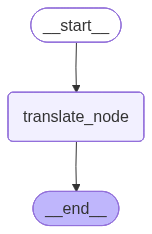

In [7]:
subgraph_workflow = StateGraph(Subgraph)
subgraph_workflow.add_node('translate_node', translate_node)

# Adding edges
subgraph_workflow.add_edge(START, 'translate_node')
subgraph_workflow.add_edge('translate_node', END)

subgraph = subgraph_workflow.compile()
subgraph

Defining Parent State

In [8]:
class ParentState(TypedDict):
    question: str
    english_answer: str
    hindi_answer: str

In [9]:
# Defining node to generate answer.
def answer_node(state: ParentState):
    prompt = f'''You are an helpful assistant. Answer the question below.

    Question: {state['question']}
'''
    
    response = model.invoke(prompt)

    return{"english_answer": response.content.strip()}

In [10]:
# Defining the translation node
def translate_answer(state: ParentState):

    # English text to be translated
    input_text = state['english_answer']

    # Invoking the subgraph for translation
    subgraph_response = subgraph.invoke({'input_text': input_text})
    response = subgraph_response['translated_text'].strip()

    return {"hindi_answer": response}

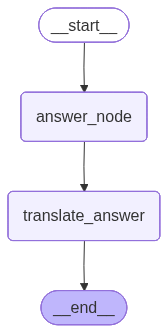

In [11]:
parent_workflow = StateGraph(ParentState)
parent_workflow.add_node("answer_node", answer_node)
parent_workflow.add_node("translate_answer", translate_answer)

# Adding edges
parent_workflow.add_edge(START, "answer_node")
parent_workflow.add_edge("answer_node", "translate_answer")

final_workflow = parent_workflow.compile()
final_workflow

In [12]:
result = final_workflow.invoke(
    {
        'question':
        "Make me believe that I will find Bhagwan Krishna if I do 'Naam Japp'. Consider all indian shashtras and sayings of various saints while answering this question."
        }
)

In [13]:
result
# This returns all the keys

{'question': "Make me believe that I will find Bhagwan Krishna if I do 'Naam Japp'. Consider all indian shashtras and sayings of various saints while answering this question.",
 'english_answer': 'In the Indian scriptures and teachings of saints, it is believed that chanting the name of the divine with true devotion and sincerity can lead one to spiritual enlightenment and bring them closer to the presence of the divine being. \n\nIn the Bhagavad Gita, Lord Krishna himself emphasizes the power of chanting his name, stating "Those who worship me with steadfast devotion through their meditation, and always chanting My divine glories, I swiftly deliver them from the mires of the ocean of life and death." (BG 12.6)\n\nSimilarly, many saints and spiritual leaders in India have emphasized the importance of \'Naam Japp\' in seeking the divine presence. Swami Vivekananda once said, "Repeat the name of the Lord, and let His name be the only wealth you possess." \n\nSaint Tulsidas, a devotee of 

In [14]:
print(result['hindi_answer'])

भारतीय शास्त्रों और संतों की शिक्षाओं में माना जाता है कि दिव्य के नाम का लवांय उदात्तता और ईमानदारी से जो कोई बोलता है, उसे आध्यात्मिक जागरूकता की ओर ले जा सकता है और उसे दिव्य प्राणिक का अनुभव करा सकता है।

भगवद गीता में, स्वयं भगवान कृष्ण अपने नाम के महत्व को जोर देते हैं, कहते हैं "जो मेरा ध्यान करके अपने उदासीन भक्ति के साथ पूजन करते हैं, और हमेशा मेरी दिव्य गुणों की जय करते हैं, मैं उन्हें जीवन और मौत की जलसीमा से तत्काल मुक्त कर देता हूं।" (भगवद गीता 12.6)

इसी तरह, भारत में कई संत और आध्यात्मिक नेताओं ने दिव्य प्राणिक के ढूँढने में 'नाम जप' का महत्व जोर दिया है। स्वामी विवेकानंद ने कहा था, "भगवान का नाम बार-बार दोहराओ, और उसका नाम ही तुम्हारी एकमात्र संपत्ति हो जाए।"

संत तुलसीदास, प्रभु राम के भक्त, भी अपने कामों में दिव्य नाम का जप करने की शक्ति को जोर देते हैं, कहते हैं "भगवान के नाम को बार-बार पुनरावृत्ति करने वाले भक्त के लिए यह जैविक अमृत की तरह है।"

इसलिए, भारतीय शास्त्रों और संतों के उपदेशों और विश्वासों पर आधारित है कि सच्ची भक्ति और विश्वास के साथ 'नाम जप' में व्यस्त